# Failure analysis: where and why the models get the growth pattern wrong

**Dev patients only** (167 train+val patients, out-of-fold predictions from the 15 fixed CV folds). The test set is never read here.

What this notebook shows:
1. Where balanced accuracy is lost: recall per class, confusion matrices, and how often *at least one* model is right.
2. What the hard patients have in common: diagnosis (AIS / MIA / IA), conflicting labels across a patient's slides, number of slides.
3. Example slides: thumbnail, attention heat maps (where each model looks) and the top-attended tiles.

Attention maps come from one network per held-out fold, trained with the round's recipe on that fold's training patients only, so it never saw the shown patient's label.

Run: `uv run --group notebooks jupyter nbconvert --to notebook --execute --inplace notebooks/failure_analysis.ipynb` (needs the GPU for the attention part, power limit <= 450 W).

In [1]:
# Parameters
ROUND = "v7"                 # round whose selected models are analysed (artifacts/results/<ROUND>)
FUSED_STREAMS = "joint"      # "per_model" (v5/v6 fused inputs) or "joint" (v7 tile-level fusion inputs)
PAIRS = [("Lepidic", "In situ"), ("Papillary", "Acinar")]   # true class -> wrongly predicted class
N_WRONG = 2                  # wrong examples per pair (plus one correct reference of each class)

import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from luad.config import repo_path
from luad.data.dataset import CLASSES, load_dev_set
from luad.eval import failure as fa

pd.set_option("display.precision", 2); pd.set_option("display.width", 160)
SURF, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"
BLUES = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
HEAT = LinearSegmentedColormap.from_list("heat", ["#cde2fb00", "#3987e5aa", "#0d366bff"])   # transparent -> dark blue
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "font.size": 9,
                     "axes.edgecolor": "#e4e3df", "text.color": INK, "axes.labelcolor": INK2})
OUT = repo_path(f"artifacts/figures/failure_{ROUND}"); OUT.mkdir(parents=True, exist_ok=True)

In [2]:
# Out-of-fold probabilities of the round's selected rows (cached: they take about a minute)
ds = load_dev_set()
ds_f = load_dev_set(fusion=True) if FUSED_STREAMS == "joint" else ds
cache = repo_path(f"artifacts/results/{ROUND}/failure/oof.npz")
if cache.exists():
    oof = dict(np.load(cache))
else:
    oof = fa.round_oof(f"artifacts/results/{ROUND}", ds, ds_f)
    cache.parent.mkdir(parents=True, exist_ok=True); np.savez_compressed(cache, **oof)
y = ds.y
print({k: v.shape for k, v in oof.items()})

{'uni2h': (3, 167, 7), 'virchow2': (3, 167, 7), 'hoptimus1': (3, 167, 7), 'uni2h+meta': (3, 167, 7), 'virchow2+meta': (3, 167, 7), 'hoptimus1+meta': (3, 167, 7), 'fused': (3, 167, 7)}


## 1. Where balanced accuracy is lost

In [3]:
rec = fa.recall_table(y, oof)
rec.loc["at least 1 of 3 image models right (upper bound)"] = fa.any_right_table(y, oof, ["uni2h", "virchow2", "hoptimus1"])
rec.columns = [c if c != "balanced accuracy" else "BA" for c in rec.columns]
print("patients per class:", dict(zip(CLASSES, np.bincount(y))))
rec.round(2)

patients per class: {'Acinar': np.int64(26), 'Cribriform': np.int64(12), 'In situ': np.int64(36), 'Lepidic': np.int64(17), 'Micropapillary': np.int64(21), 'Papillary': np.int64(32), 'Solid': np.int64(23)}


,Acinar,Cribriform,In situ,Lepidic,Micropapillary,Papillary,Solid,BA
uni2h,0.51,0.47,0.79,0.35,0.43,0.35,0.54,0.49
virchow2,0.31,0.58,0.82,0.53,0.51,0.14,0.57,0.49
hoptimus1,0.55,0.61,0.89,0.18,0.43,0.15,0.57,0.48
uni2h+meta,0.50,0.53,0.78,0.31,0.43,0.33,0.54,0.49
virchow2+meta,0.31,0.58,0.82,0.53,0.44,0.15,0.57,0.49
hoptimus1+meta,0.55,0.61,0.90,0.16,0.43,0.18,0.55,0.48
fused,0.47,0.53,0.87,0.29,0.54,0.25,0.64,0.51
at least 1 of 3 image models right (upper bound),0.67,0.72,0.94,0.75,0.75,0.44,0.72,0.71


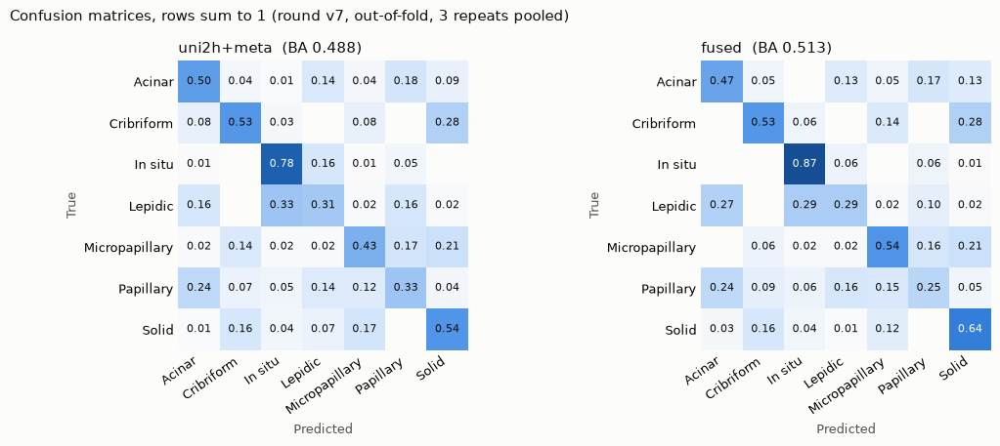

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, name in zip(axes, ["uni2h+meta", "fused"]):
    cm = fa.confusion(y, oof[name])
    ax.imshow(cm.values, cmap=BLUES, vmin=0, vmax=1)
    for i in range(7):
        for j in range(7):
            if cm.values[i, j] >= 0.005:
                ax.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if cm.values[i, j] > 0.62 else INK)
    ax.set_xticks(range(7), CLASSES, rotation=35, ha="right"); ax.set_yticks(range(7), CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(f"{name}  (BA {np.mean(np.diag(cm.values)):.3f})", loc="left")
fig.suptitle(f"Confusion matrices, rows sum to 1 (round {ROUND}, out-of-fold, 3 repeats pooled)", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(OUT / "confusion.png", dpi=170); plt.show()

## 2. What the hard patients have in common

In [5]:
cases = fa.case_table(ds, y, oof)
lep = cases[cases.true == "Lepidic"]
print("Lepidic patients: diagnosis x fused prediction")
display(pd.crosstab(lep.diagnosis, lep.fused_pred, margins=True))
print("In situ patients: diagnosis", cases[cases.true == "In situ"].diagnosis.value_counts().to_dict())

Lepidic patients: diagnosis x fused prediction


fused_pred,Acinar,In situ,Lepidic,Papillary,All
diagnosis,,,,,
IA,4,2,5,2,13
MIA,1,3,0,0,4
All,5,5,5,2,17


In situ patients: diagnosis {'AIS': 36}


In [6]:
print("Patients whose own slides carry different labels (we use the selected slide's label):")
display(cases[cases.conflicting_labels][["wsi_id", "true", "fused_pred", "all_labels", "diagnosis", "p_true", "p_pred"]])

Patients whose own slides carry different labels (we use the selected slide's label):


,wsi_id,true,fused_pred,all_labels,diagnosis,p_true,p_pred
12,WSI-380,Acinar,Solid,Acinar;Solid,IA,0.14,0.34
69,WSI-347,Lepidic,In situ,Lepidic;Papillary,IA,0.29,0.33
73,WSI-398,Lepidic,In situ,Acinar;Lepidic,MIA,0.21,0.47
74,WSI-401,Lepidic,Acinar,Acinar;Lepidic,IA,0.22,0.38


In [7]:
t = cases.assign(correct=cases.true == cases.fused_pred, several_slides=cases.n_slides > 1)
summary = t.groupby("true").agg(patients=("wsi_id", "size"), fused_recall=("correct", "mean"),
                                share_with_more_slides=("several_slides", "mean"), median_tiles=("n_tiles", "median"),
                                median_age=("age", "median"), share_female=("sex", lambda s: (s == "Female").mean()))
summary.round(2)

,patients,fused_recall,share_with_more_slides,median_tiles,median_age,share_female
true,,,,,,
Acinar,26,0.50,0.42,11433.0,53.0,0.69
Cribriform,12,0.58,0.75,12846.0,66.5,0.33
In situ,36,0.89,0.61,8670.0,49.0,0.83
Lepidic,17,0.29,0.53,11545.0,57.0,0.59
Micropapillary,21,0.57,0.95,12422.0,57.0,0.43
Papillary,32,0.28,0.88,11305.5,59.0,0.66
Solid,23,0.65,0.74,13842.0,57.0,0.43


In [8]:
print("Recall when the patient has 1 slide vs several (we always use one slide):")
t.groupby(["several_slides"]).correct.mean().round(2)

Recall when the patient has 1 slide vs several (we always use one slide):


several_slides
False    0.55
True     0.56
Name: correct, dtype: float64

## 3. Example slides\n\nFor each pair: the patients the fused model most confidently gets wrong, then one correctly classified patient of each class for comparison. Heat maps: darker blue = more attention (scaled so the top 0.5% of tiles are darkest). Bottom row: the 6 tiles with the most attention (tile-level fusion attention when available, else UNI2-h).

In [9]:
examples = {pair: fa.pick_examples(cases, *pair, n_wrong=N_WRONG) for pair in PAIRS}
wanted = sorted({w for ws in examples.values() for w in ws})
display(cases.set_index("wsi_id").loc[wanted, ["true", "fused_pred", "p_true", "p_pred", "diagnosis", "all_labels",
                                               "n_slides", "n_tiles", "uni2h_right", "virchow2_right", "hoptimus1_right"]])

,true,fused_pred,p_true,p_pred,diagnosis,all_labels,n_slides,n_tiles,uni2h_right,virchow2_right,hoptimus1_right
wsi_id,,,,,,,,,,,
WSI-152,Papillary,Papillary,0.30,0.30,IA,Papillary,2,8846,True,False,True
WSI-222,Papillary,Acinar,0.16,0.25,IA,Papillary,2,12117,False,False,False
WSI-311,Lepidic,Lepidic,0.30,0.30,IA,Lepidic,2,16406,False,True,True
WSI-318,Lepidic,In situ,0.17,0.54,IA,Lepidic,2,6710,False,True,False
WSI-356,Papillary,Acinar,0.18,0.29,IA,Papillary,1,7497,False,False,False
WSI-360,Acinar,Acinar,0.41,0.41,IA,Acinar,1,14115,True,True,True
WSI-39,In situ,In situ,0.71,0.71,AIS,In situ,2,5121,True,True,True
WSI-398,Lepidic,In situ,0.21,0.47,MIA,Acinar;Lepidic,2,13489,False,False,False


In [10]:
import torch
from luad.config import load_config
from luad.embeddings.abmil import MultiViewBank
from luad.utils.gpu import require_power_limit
require_power_limit(load_config("embeddings")["run"]["max_power_w"])
bank = MultiViewBank.from_h5(load_config("experiments")["models"], ds.wsi_ids, repo_path(load_config("embeddings")["paths"]["out_dir"]))
att = {kind: fa.attention_maps(ds, wanted, bank, kind) for kind in ["uni2h", "hoptimus1", "joint"]}
del bank; torch.cuda.empty_cache()

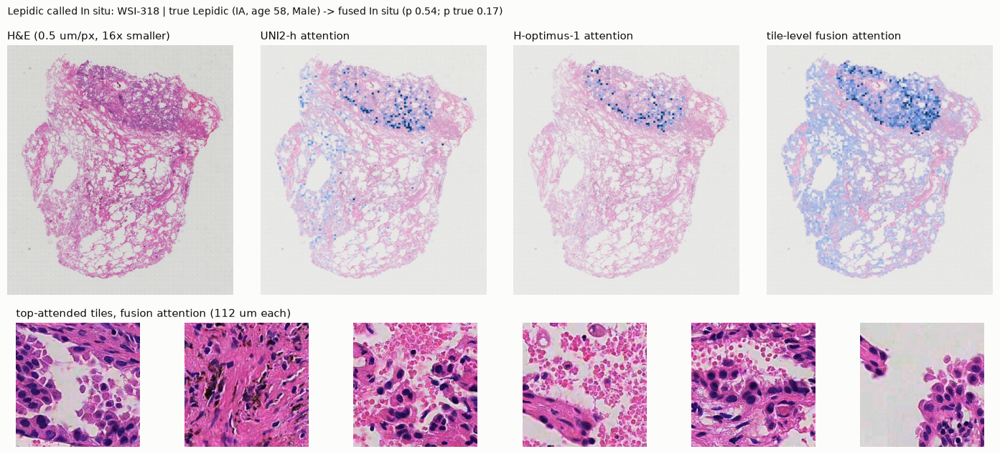

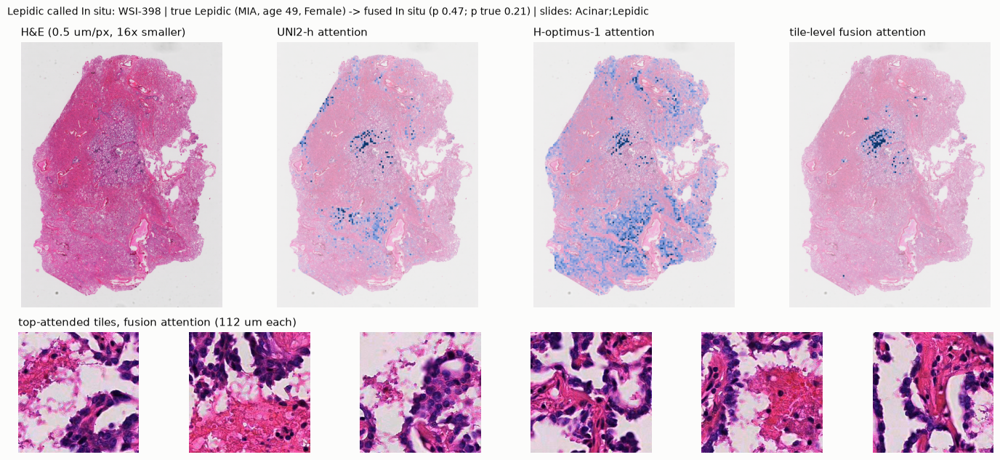

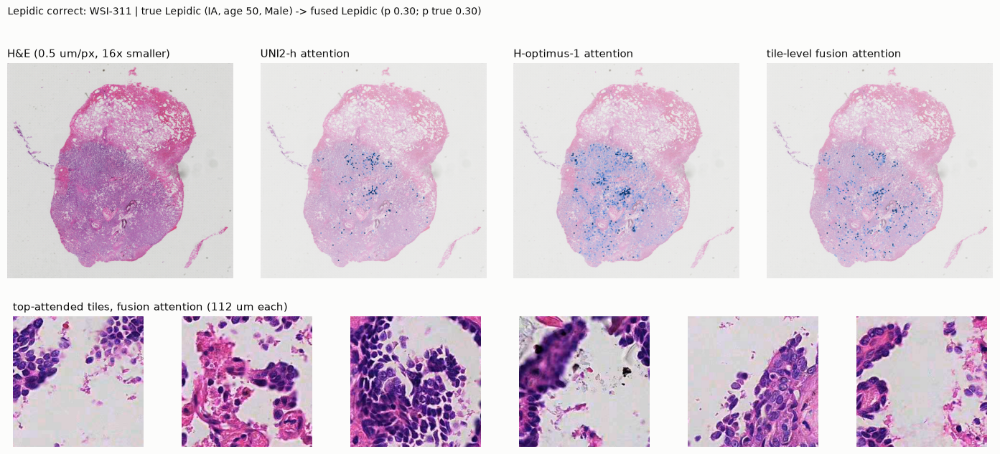

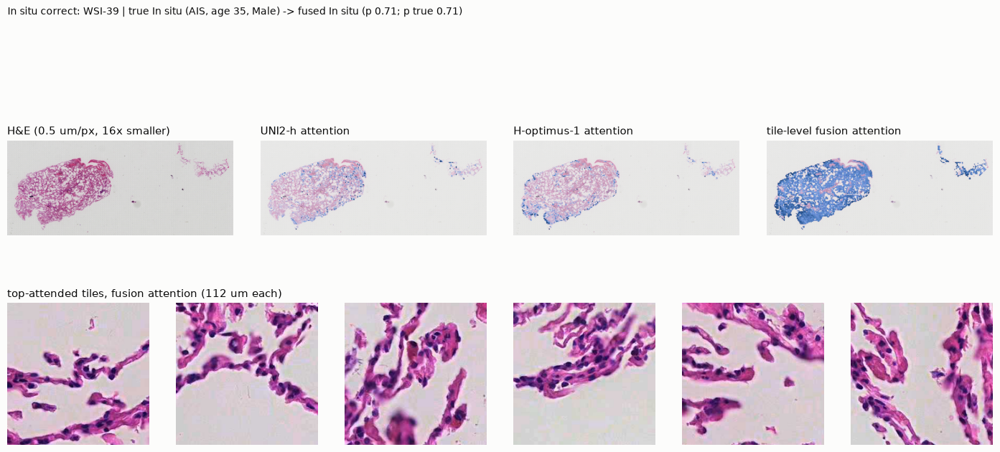

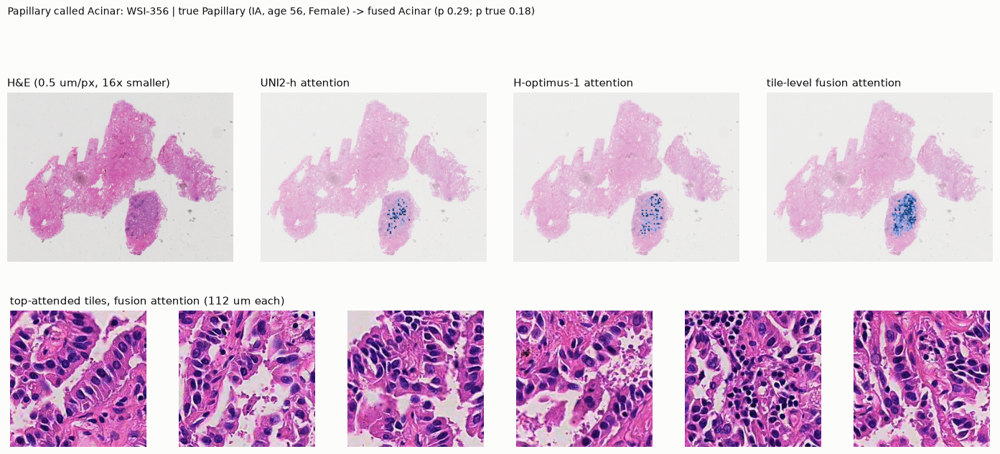

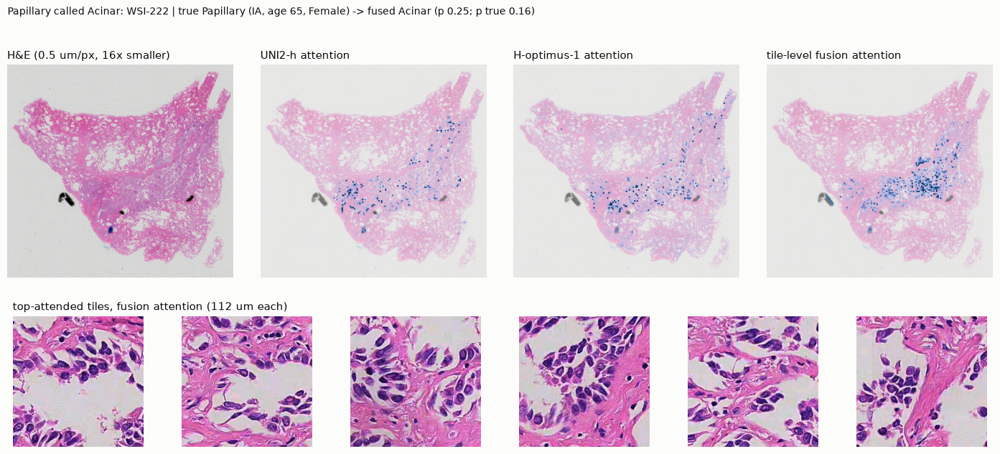

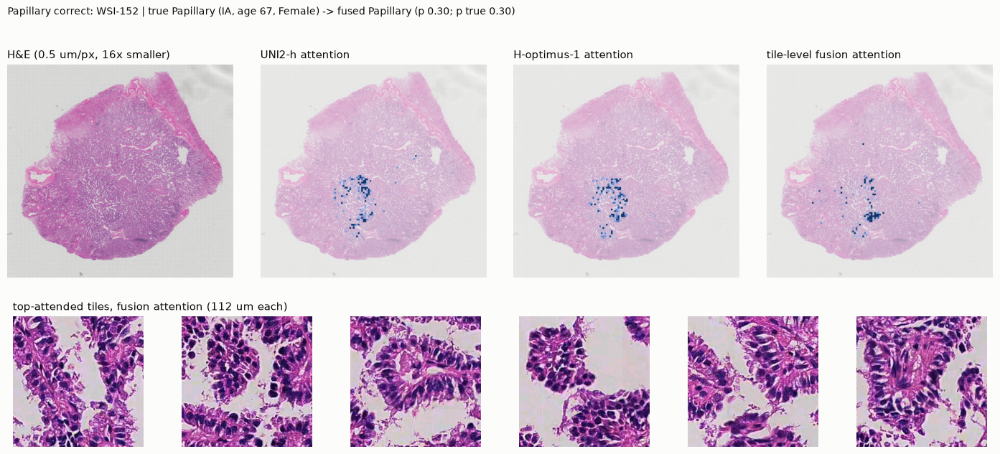

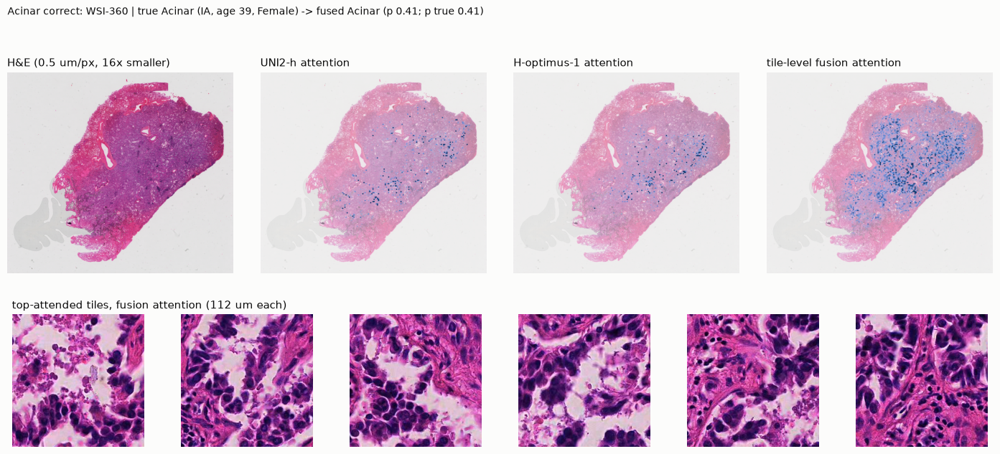

In [11]:
NAMES = {"uni2h": "UNI2-h attention", "hoptimus1": "H-optimus-1 attention", "joint": "tile-level fusion attention"}
def show(wsi, tag):
    r = cases.set_index("wsi_id").loc[wsi]
    thumb, heats, tiles = fa.slide_pictures(wsi, {k: att[k][wsi] for k in att})
    fig = plt.figure(figsize=(14, 6.4))
    gs = fig.add_gridspec(2, 12, height_ratios=[2.2, 1])
    ax = fig.add_subplot(gs[0, 0:3]); ax.imshow(thumb); ax.set_title("H&E (0.5 um/px, 16x smaller)", loc="left"); ax.axis("off")
    for n, kind in enumerate(["uni2h", "hoptimus1", "joint"]):
        ax = fig.add_subplot(gs[0, 3 * (n + 1):3 * (n + 2)])
        ax.imshow(thumb, alpha=0.55); ax.imshow(heats[kind], cmap=HEAT, vmin=0, vmax=1); ax.axis("off")
        ax.set_title(NAMES[kind], loc="left")
    for n in range(6):
        ax = fig.add_subplot(gs[1, 2 * n:2 * n + 2]); ax.imshow(tiles["joint"][n]); ax.axis("off")
        if n == 0: ax.set_title("top-attended tiles, fusion attention (112 um each)", loc="left")
    lbl = f" | slides: {r.all_labels}" if r.conflicting_labels else ""
    fig.suptitle(f"{tag}: {wsi} | true {r.true} ({r.diagnosis}, age {r.age}, {r.sex}) -> fused {r.fused_pred} "
                 f"(p {r.p_pred:.2f}; p true {r.p_true:.2f}){lbl}", x=0.01, ha="left", fontsize=10)
    fig.tight_layout(); fig.savefig(OUT / f"{tag.replace(' ', '_')}_{wsi}.png", dpi=150); plt.show()

for (true, pred), ws in examples.items():
    tags = [f"{true} called {pred}"] * N_WRONG + [f"{true} correct", f"{pred} correct"]
    for w, tag in zip(ws, tags):
        show(w, tag)

## Notes for reading the figures

- The heat maps show where each network puts its weight; they are not proof of what the network "understood".
- Compare the wrong cases with the correct references of both classes: do the top-attended tiles look more like the predicted class?
- Check the facts table above (diagnosis, conflicting labels, number of slides) before drawing a conclusion from one slide.